
# Correlation Pipeline Test

This notebook loads matched **transcriptomics** and **proteomics** matrices, those should be inside the folder 'data' at same level of this notebook, downsamples to a controllable subset (samples, genes), and runs `compute_correlation_for_protein` from **`corr_functions.py`**. It also saves the resulting correlation row to the usual `data/correlations/` folder and shows a quick distribution plot of non‑zero correlations.

In [ ]:

# --- Controls tweak ---
N_SAMPLES = 200        # Set to None to keep all samples
N_GENES = 500          # Set to None to keep all genes
BOOTSTRAP = False      # True to enable bootstrap CI logic in compute_correlation_for_protein
N_BOOTSTRAPS = 200     # Only used if BOOTSTRAP=True
P_THRESHOLD = 0.05     # Only used if BOOTSTRAP=False
RANDOM_SEED = 42       # For reproducibility of sub-sampling

#force a specific protein; set to None to auto-pick a good one
FORCE_PROTEIN_NAME = "A2M"


In [5]:

from pathlib import Path
import sys
import numpy as np
import pandas as pd
from joblib import load
import matplotlib.pyplot as plt
from time import perf_counter


# Resolve paths relative to this notebook. If you keep the notebook in the same folder
# as corr_functions.py (as in your screenshot), this will work out-of-the-box.
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
CORR_DIR = DATA_DIR / "correlations"

TRANSCRIPTOMICS_FILE = DATA_DIR / "transcriptomics_filtered.joblib"
PROTEOMICS_FILE = DATA_DIR / "proteomics_matched.joblib"

# Make sure we can import corr_functions.py from the current folder
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from corr_functions import compute_correlation_for_protein

print(f"Project root: {ROOT}")
print(f"Data dir:     {DATA_DIR}")


Project root: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\02. correlations\computation
Data dir:     c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\02. correlations\computation\data


In [6]:

# Load matrices
tx_path = TRANSCRIPTOMICS_FILE
px_path = PROTEOMICS_FILE

print("Loading matrices...")
transcriptomics = load(tx_path)
proteomics = load(px_path)

# Set friendly labels (not strictly required, but nice to have)
transcriptomics.index.name = "samples"
proteomics.index.name = "samples"
transcriptomics.columns.name = "genes"
proteomics.columns.name = "proteins"

print("Loaded:")
print(f"  transcriptomics: {transcriptomics.shape}")
print(f"  proteomics:      {proteomics.shape}")

# Quick sanity checks
assert isinstance(transcriptomics, pd.DataFrame), "Transcriptomics must be a DataFrame"
assert isinstance(proteomics, pd.DataFrame), "Proteomics must be a DataFrame"

# Ensure overlapping sample space
common_samples = transcriptomics.index.intersection(proteomics.index)
print(f"Common samples: {len(common_samples)}")
if len(common_samples) == 0:
    raise ValueError("No overlapping samples between transcriptomics and proteomics.")


Loading matrices...
Loaded:
  transcriptomics: (369, 22614)
  proteomics:      (369, 5113)
Common samples: 369


In [7]:

# --- Subset selection ---
np.random.seed(RANDOM_SEED)

# Sample subset
if N_SAMPLES is None:
    chosen_samples = common_samples
else:
    n = min(int(N_SAMPLES), len(common_samples))
    chosen_samples = pd.Index(np.random.choice(common_samples, size=n, replace=False))

# Gene subset
if N_GENES is None:
    chosen_genes = transcriptomics.columns
else:
    g = min(int(N_GENES), transcriptomics.shape[1])
    chosen_genes = pd.Index(np.random.choice(transcriptomics.columns, size=g, replace=False))

t_sub = transcriptomics.loc[chosen_samples, chosen_genes]
p_sub = proteomics.loc[chosen_samples]

print("Subset shapes:")
print(f"  transcriptomics subset: {t_sub.shape}")
print(f"  proteomics subset:      {p_sub.shape}")


Subset shapes:
  transcriptomics subset: (200, 500)
  proteomics subset:      (200, 5113)


In [8]:

# Pick a protein with the most observed (non-null) values on the chosen samples,
# unless the user forces a specific protein name.
if FORCE_PROTEIN_NAME is not None:
    protein_name = FORCE_PROTEIN_NAME
    if protein_name not in p_sub.columns:
        raise ValueError(f"Requested protein '{protein_name}' not found in proteomics subset.")
else:
    nonnull_counts = p_sub.notna().sum().sort_values(ascending=False)
    protein_name = nonnull_counts.index[0]

print(f"Protein selected: {protein_name}")
print(f"Non-null values for {protein_name}: {p_sub[protein_name].notna().sum()}")


Protein selected: A2M
Non-null values for A2M: 200


In [9]:

print("Running compute_correlation_for_protein...")
t0 = perf_counter()
corr_row = compute_correlation_for_protein(
    transcriptomics=t_sub,
    proteomics=p_sub,
    protein_name=protein_name,
    p_threshold=P_THRESHOLD,
    bootstrap=BOOTSTRAP,
    n_bootstraps=N_BOOTSTRAPS,
)
elapsed = perf_counter() - t0
print(f"Done in {elapsed:.2f}s")

# Basic inspection
nonzero = corr_row[corr_row != 0].sort_values(ascending=False)
print(f"Non-zero correlations: {nonzero.shape[0]} / {corr_row.shape[0]} genes")
display(nonzero.head(10))


Running compute_correlation_for_protein...
Done in 0.59s
Non-zero correlations: 145 / 500 genes


TNS2          0.368696
AC244517.4    0.361051
TBC1D9        0.360174
RBMS3-AS3     0.347872
APMAP         0.333163
TUBA1A        0.317486
GPR161        0.314851
IFT22         0.311607
C1QL4         0.311344
AC091564.4    0.298821
dtype: float64

If the user wants to run correlation on a protein list, it can be done with the next cell.

In [10]:
protein_list = ["A2M"]

In [11]:
results, timings = {}, {}
for protein_name in protein_list:
    print(f"\nRunning compute_correlation_for_protein for: {protein_name}")
    t0 = perf_counter()
    s = compute_correlation_for_protein(
        transcriptomics=t_sub, proteomics=p_sub, protein_name=protein_name,
        p_threshold=P_THRESHOLD, bootstrap=BOOTSTRAP, n_bootstraps=N_BOOTSTRAPS
    )
    elapsed = perf_counter() - t0
    print(f"Done in {elapsed:.2f}s"); timings[protein_name] = elapsed
    s = s if isinstance(s, pd.Series) else pd.Series(s)
    nonzero = s[s != 0].sort_values(ascending=False)
    print(f"Non-zero correlations: {nonzero.shape[0]} / {s.shape[0]} genes"); display(nonzero.head(10))
    results[protein_name] = s
corr_df = pd.DataFrame(results)
timings = pd.Series(timings, name="seconds").sort_values()



Running compute_correlation_for_protein for: A2M
Done in 0.64s
Non-zero correlations: 145 / 500 genes


TNS2          0.368696
AC244517.4    0.361051
TBC1D9        0.360174
RBMS3-AS3     0.347872
APMAP         0.333163
TUBA1A        0.317486
GPR161        0.314851
IFT22         0.311607
C1QL4         0.311344
AC091564.4    0.298821
dtype: float64

In [ ]:

# # Save to the usual correlations folder, but with a '_subset' suffix so it doesn't collide with full runs.
# CORR_DIR.mkdir(parents=True, exist_ok=True)
# out_path = CORR_DIR / f"{protein_name}_corr_subset.csv"

# # one row, columns = genes
# corr_row.to_frame().T.to_csv(out_path)
# print(f"Saved subset correlation row to: {out_path}")
# out_path


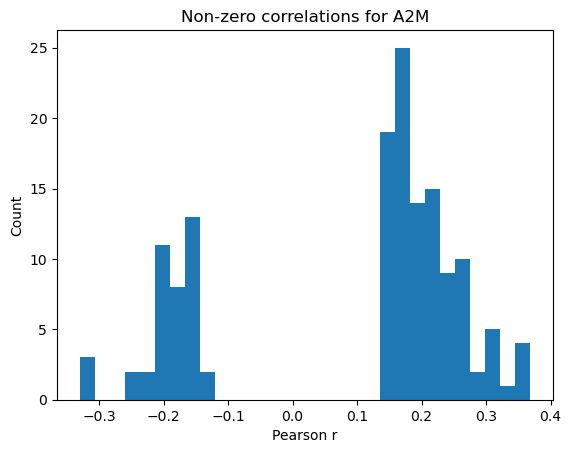

In [12]:

# Quick distribution plot of the non-zero correlations (if any)
vals = nonzero.values
if len(vals) > 0:
    plt.figure()
    plt.hist(vals, bins=30)
    plt.title(f"Non-zero correlations for {protein_name}")
    plt.xlabel("Pearson r")
    plt.ylabel("Count")
    plt.show()
else:
    print("No non-zero correlations to plot.")
